# **Step-1: Import Libraries**

In [185]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [186]:
import warnings
warnings.filterwarnings("ignore")

In [187]:
# Help For Loading Dataset
from datasets import load_dataset

# **Step-2: Load Dataset**

In [188]:
ds = load_dataset("dair-ai/emotion")
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [189]:
# Training Data
train_text = ds["train"]["text"]
train_label = ds["train"]["label"]

In [190]:
# Testing Data
test_text = ds["test"]["text"]
test_label = ds["test"]["label"]

In [191]:
# Label Names
label_names = ds["train"].features["label"].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [192]:
for i in train_label:
  print(label_names[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

In [193]:
df_train = pd.DataFrame(
    {
        "text" : train_text,
        # List Comprehension
        "label" : [label_names[i] for i in train_label]
    }
)

In [194]:
df_test = pd.DataFrame(
    {
        "text" : test_text,
        # List Comprehension
        "label" : [label_names[i] for i in test_label]
    }
)

# **Step-3: EDA**

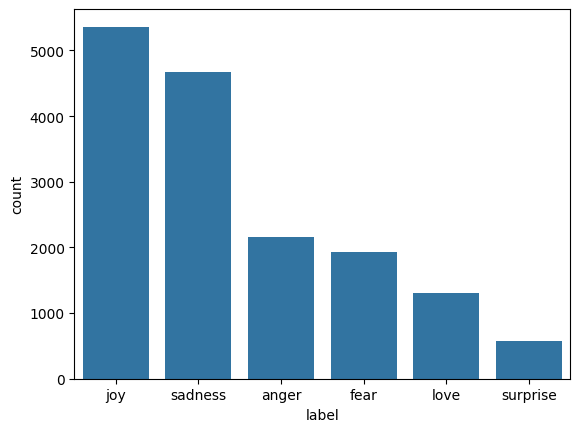

In [195]:
# Count Plot
sns.countplot(x = df_train["label"], order = df_train["label"].value_counts().index )
plt.show()

# **Step-4: Data Preprocessing - Using NLP**

**4.1: Tokenization**

In [196]:
df_train["text"].head()

,text
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy


In [197]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [198]:
# Set Vocabulary Size
max_words = 10000

In [199]:
# Make a tokenizer (Vocabulary)
tokenizer = Tokenizer(num_words=max_words, oov_token = "<unk>")

In [200]:
# Train on Training Data (If we did it on testing data, it can cause Data Leakage)
tokenizer.fit_on_texts(df_train["text"])

In [201]:
# For removing words and keep only their numbers
train_sequence = tokenizer.texts_to_sequences(df_train["text"])
test_sequence = tokenizer.texts_to_sequences(df_test["text"])

In [202]:
# For Calculating No. of Words in the Longest Sentence
max_len = df_train["text"].str.split().str.len().max()
print(max_len)

66


In [203]:
# Covert Into Padding
padded_train_sequence = pad_sequences(train_sequence, maxlen=max_len, padding="post", truncating="post")
padded_test_sequence = pad_sequences(test_sequence, maxlen=max_len, padding="post", truncating="post")

In [204]:
padded_train_sequence

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]], dtype=int32)

In [205]:
# Conveting Label Data Into Array (Numbers)
train_labels = np.array(train_label)
test_labels = np.array(test_label)

In [206]:
train_labels

array([0, 0, 3, ..., 1, 3, 0])

In [207]:
# Get No. of Classes of Label Data
num_classes = len(np.unique(train_labels))
num_classes

6

# **Step-5: Shared Training Utilties - Class Weights**

In [208]:
from sklearn.utils import class_weight

In [209]:
# weight = total_samples / (Num_classes * samples_in_that_class)
class_weights = class_weight.compute_class_weight(
    class_weight = "balanced",
    classes = np.unique(train_labels),
    y = train_labels
)

In [210]:
# Class_Weights Assign To Each Label
class_weight_dic = dict(enumerate(class_weights))

In [211]:
from tensorflow.keras.callbacks import EarlyStopping

# Early Stopping Callback Setup
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# **Step-6: Phase 1 - Plain Models**

In [213]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, LSTM, GRU

**6.1: RNN**

In [214]:
model_RNN = Sequential(
    [
    Embedding(input_dim = max_words, output_dim = 128, input_length = max_len),
    SimpleRNN(units = 128, return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation = "softmax")
    ]
)

In [215]:
model_RNN.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics = ["accuracy"]
)

In [217]:
model_RNN.fit(
    padded_train_sequence,
    train_labels,
    validation_data = (padded_test_sequence, test_labels),
    epochs = 20,
    batch_size = 32,
    callbacks = [early_stop],
    class_weight = class_weight_dic
)

rnn_loss, rnn_accuracy = model_RNN.evaluate(padded_test_sequence, test_labels)
print(f"Accuracy: {rnn_accuracy}")
print(f"Loss: {rnn_loss}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.1531 - loss: 1.9216 - val_accuracy: 0.0850 - val_loss: 1.7982
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.1538 - loss: 1.8100 - val_accuracy: 0.1060 - val_loss: 1.8111
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.1488 - loss: 1.7974 - val_accuracy: 0.0825 - val_loss: 1.8063
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.1482 - loss: 1.7969 - val_accuracy: 0.0365 - val_loss: 1.8133
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0850 - loss: 1.7982
Accuracy: 0.08500000089406967
Loss: 1.7982168197631836


**6.2: Standard LSTM**

In [218]:
model_LSTM = Sequential(
    [
    Embedding(input_dim = max_words, output_dim = 128, input_length = max_len),
    LSTM(units = 128, return_sequences = True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation = "softmax")
    ]
)

In [220]:
model_LSTM.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics = ["accuracy"]
)

In [221]:
model_LSTM.fit(
    padded_train_sequence,
    train_labels,
    validation_data = (padded_test_sequence, test_labels),
    epochs = 20,
    batch_size = 32,
    callbacks = [early_stop],
    class_weight = class_weight_dic
)

lstm_loss, lstm_accuracy = model_LSTM.evaluate(padded_test_sequence, test_labels)
print(f"Accuracy: {lstm_accuracy}")
print(f"Loss: {lstm_loss}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.1442 - loss: 1.7953 - val_accuracy: 0.2900 - val_loss: 1.7822
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1720 - loss: 1.7937 - val_accuracy: 0.1375 - val_loss: 1.7911
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1467 - loss: 1.7935 - val_accuracy: 0.3080 - val_loss: 1.7731
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1637 - loss: 1.7934 - val_accuracy: 0.1125 - val_loss: 1.7945
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.1497 - loss: 1.7934 - val_accuracy: 0.1120 - val_loss: 1.7976
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1621 - loss: 1.7931 - val_accuracy: 0.1120 - val_loss: 1.7896
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3080 - loss: 1.7731
Accuracy: 0.30799999833106995
Loss: 1.77305006980896


**6.3: Standard GRU**

In [222]:
model_GRU = Sequential(
    [
    Embedding(input_dim = max_words, output_dim = 128, input_length = max_len),
    GRU(units = 128, return_sequences = True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation = "softmax")
    ]
)

In [223]:
model_GRU.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics = ["accuracy"]
)

In [224]:
model_GRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data = (padded_test_sequence, test_labels),
    epochs = 20,
    batch_size = 32,
    callbacks = [early_stop],
    class_weight = class_weight_dic
)

gru_loss, gru_accuracy = model_GRU.evaluate(padded_test_sequence, test_labels)
print(f"Accuracy: {gru_accuracy}")
print(f"Loss: {gru_loss}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1418 - loss: 1.7968 - val_accuracy: 0.0795 - val_loss: 1.8034
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1443 - loss: 1.7949 - val_accuracy: 0.0330 - val_loss: 1.7898
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1442 - loss: 1.7955 - val_accuracy: 0.1375 - val_loss: 1.7841
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0795 - loss: 1.8034
Accuracy: 0.0794999971985817
Loss: 1.8034260272979736


In [225]:
# Model Comparison
pd.DataFrame(
    {
        "Model" : ["RNN", "LSTM", "GRU"],
        "Accuracy" : [rnn_accuracy, lstm_accuracy, gru_accuracy],
        "Loss" : [rnn_loss, lstm_loss, gru_loss]
    }
).sort_values(by = "Accuracy", ascending = False)

,Model,Accuracy,Loss
1,LSTM,0.3080,1.773050
0,RNN,0.0850,1.798217
2,GRU,0.0795,1.803426


# **Step-7: Applying Bidirectional Model**

**7.1: Bidirectional GRU**

In [226]:
from tensorflow.keras.layers import Bidirectional

In [227]:
model_BiGRU = Sequential([
    Embedding(
        input_dim = max_words,
        output_dim = 300,
        input_length = max_len
    ),

    Bidirectional(
        GRU(128)
    ),

    Dropout(0.5),

    Dense(
        num_classes,
        activation="softmax"
    )
])

In [228]:
model_BiGRU.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [229]:
model_BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dic,
    callbacks=[early_stop]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5611 - loss: 0.9927 - val_accuracy: 0.8795 - val_loss: 0.3512
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9168 - loss: 0.2299 - val_accuracy: 0.9065 - val_loss: 0.2249
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9439 - loss: 0.1419 - val_accuracy: 0.9065 - val_loss: 0.2588
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9534 - loss: 0.1156 - val_accuracy: 0.9050 - val_loss: 0.2898
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9701 - loss: 0.0778 - val_accuracy: 0.9160 - val_loss: 0.2584


In [230]:
bigru_loss, bigru_accuracy = model_BiGRU.evaluate(
    padded_test_sequence,
    test_labels
)

print("Accuracy:", bigru_accuracy)
print("Loss:", bigru_loss)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9065 - loss: 0.2249
Accuracy: 0.906499981880188
Loss: 0.22489681839942932


**7.2: Bidirectional LSTM**

In [231]:
model_BiLSTM = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=300,
        input_length=max_len
    ),

    Bidirectional(
        LSTM(128)
    ),

    Dropout(0.5),

    Dense(
        num_classes,
        activation="softmax"
    )
])

In [232]:
model_BiLSTM.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [233]:
model_BiLSTM.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weight_dic
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5884 - loss: 1.0724 - val_accuracy: 0.8735 - val_loss: 0.4066
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9075 - loss: 0.2702 - val_accuracy: 0.8900 - val_loss: 0.3525
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9386 - loss: 0.1727 - val_accuracy: 0.8935 - val_loss: 0.3238


In [234]:
bilstm_loss, bilstm_accuracy = model_BiLSTM.evaluate(
    padded_test_sequence,
    test_labels
)

print("BiLSTM Accuracy:", bilstm_accuracy)
print("BiLSTM Loss:", bilstm_loss)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8735 - loss: 0.4066
BiLSTM Accuracy: 0.8734999895095825
BiLSTM Loss: 0.4065535068511963


**7.3: Bidirectional RNN**

In [237]:
model_BiRNN = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=300,
        input_length=max_len
    ),

    Bidirectional(
        SimpleRNN(128)
    ),

    Dropout(0.5),

    Dense(
        num_classes,
        activation="softmax"
    )
])

In [238]:
model_BiRNN.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [239]:
model_BiRNN.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weight_dic
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2241 - loss: 1.8000 - val_accuracy: 0.3800 - val_loss: 1.5862
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.5991 - loss: 1.0685 - val_accuracy: 0.6265 - val_loss: 1.0582
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7956 - loss: 0.5772 - val_accuracy: 0.7835 - val_loss: 0.7338


In [240]:
birnn_loss, birnn_accuracy = model_BiRNN.evaluate(
    padded_test_sequence,
    test_labels
)

print("BiRNN Accuracy:", birnn_accuracy)
print("BiRNN Loss:", birnn_loss)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3800 - loss: 1.5862
BiRNN Accuracy: 0.3799999952316284
BiRNN Loss: 1.586166501045227


In [241]:
# Model Comparison
result_df = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU", "BiRNN", "BiLSTM", "BiGRU"],
    "Accuracy": [rnn_accuracy, lstm_accuracy, gru_accuracy, birnn_accuracy, bilstm_accuracy, bigru_accuracy],
    "Loss": [rnn_loss, lstm_loss, gru_loss, birnn_loss, bilstm_loss, bigru_loss]
})

result_df.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Loss
5,BiGRU,0.9065,0.224897
4,BiLSTM,0.8735,0.406554
3,BiRNN,0.3800,1.586167
1,LSTM,0.3080,1.773050
0,RNN,0.0850,1.798217
2,GRU,0.0795,1.803426


# **Step-8: Save Model**

In [256]:
import pickle

# Save model
model_BiGRU.save("BiGRU_model.keras")

# Save tokenizer
with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!
